In [1]:
import sys
sys.path.insert(0, "../data_prep")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import jump_analysis as ja
from config import DATA_PATH
print("imported ok")

imported ok


In [2]:
wavs = sorted(set(Path(DATA_PATH).glob("train/**/*.WAV")) | set(Path(DATA_PATH).glob("test/**/*.WAV")))
print(DATA_PATH)
print(len(wavs), "WAV files")

/Users/ziyaahmad/Code/mouse_vocalization_2026/data
22516 WAV files


In [3]:
out = Path("jump_review"); out.mkdir(exist_ok=True)
rng = np.random.default_rng(0)
sample = rng.choice(len(wavs), size=5, replace=False)

all_rows = []
for i in sample:
    rows, audit = ja.inspect_file(wavs[i], 10, 2, out)   # threshold kHz, min frames, output folder
    print(wavs[i].name, audit["status"], "active frames:", audit["active_frames"], "jumps:", audit["candidate_jumps"])
    all_rows += rows

pd.DataFrame(all_rows)

DBA_3247_55.WAV included active frames: 87 jumps: 0
DBA_3243_713.WAV included active frames: 39 jumps: 1
DBA_3171_1152.WAV included active frames: 113 jumps: 2
DBA_3171_399.WAV included active frames: 55 jumps: 1
DBA_9858_517.WAV included active frames: 72 jumps: 1


,file,frame,time_ms,pre_khz,post_khz,signed_jump_khz,jump_khz,review_status
0,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,32,17.066667,53.437500,64.570312,11.132812,11.132812,unreviewed
1,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,67.968750,88.476562,20.507812,20.507812,unreviewed
2,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,39,20.800000,86.132812,64.101562,-22.031250,22.031250,unreviewed
3,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,85.078125,64.218750,-20.859375,20.859375,unreviewed
4,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,64,34.133333,47.343750,65.273438,17.929688,17.929688,unreviewed


In [11]:
rng = np.random.default_rng(1)
order = rng.permutation(len(wavs))
rows_all, audits = [], []
n_inc = 0
for idx in order:
    if n_inc >= 100:
        break
    p = wavs[int(idx)]
    try:
        rows, audit = ja.inspect_file(p, 10, 2, out)
    except Exception as e:
        audits.append(dict(file=str(p), status="error"))
        continue
    audits.append(audit)
    if audit["status"] == "included":
        n_inc += 1
        rows_all += rows

jumps = pd.DataFrame(rows_all)
print(n_inc, "files,", len(jumps), "jumps,", jumps["file"].nunique(), "files with jumps")

100 files, 81 jumps, 41 files with jumps


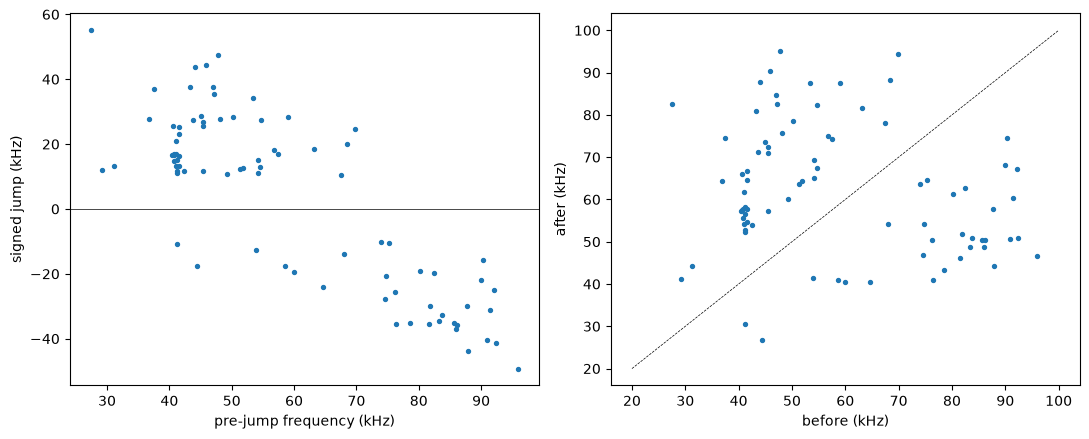

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(jumps["pre_khz"], jumps["signed_jump_khz"], s=8)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("pre-jump frequency (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[1].scatter(jumps["pre_khz"], jumps["post_khz"], s=8)
ax[1].plot([20, 100], [20, 100], "k--", lw=0.5)
ax[1].set_xlabel("before (kHz)"); ax[1].set_ylabel("after (kHz)")
plt.tight_layout(); plt.show()

In [6]:
cl = jumps[jumps["pre_khz"].between(39, 43)]
print(len(cl), "jumps start near 41 kHz")
print(cl["time_ms"].describe())
print(cl["file"].map(lambda p: Path(p).name).value_counts().head(8))

17 jumps start near 41 kHz
count    17.000000
mean     12.737255
std      13.369128
min       4.266667
25%       6.400000
50%       8.000000
75%      11.733333
max      60.800000
Name: time_ms, dtype: float64
file
DBA_3243_291.WAV     2
DBA_3170_841.WAV     1
DBA_3170_283.WAV     1
DBA_3249_446.WAV     1
DBA_3243_53.WAV      1
DBA_3172_1184.WAV    1
DBA_3170_114.WAV     1
DBA_3248_535.WAV     1
Name: count, dtype: int64


In [7]:
def call_span(path):
    times, freqs, mag, ridge, active = ja.extract_raw_ridge(Path(path))
    idx = np.flatnonzero(np.isfinite(ridge) & active)
    return times[idx[0]] * 1000, times[idx[-1]] * 1000

spans = {p: call_span(p) for p in jumps["file"].unique()}
jumps["from_start"] = jumps["time_ms"] - jumps["file"].map(lambda p: spans[p][0])
jumps["to_end"] = jumps["file"].map(lambda p: spans[p][1]) - jumps["time_ms"]
print(jumps[["from_start", "to_end"]].describe())

clean = jumps[(jumps["from_start"] > 3) & (jumps["to_end"] > 3)]
print(len(jumps), "->", len(clean), "jumps after trimming 3 ms at each end")

       from_start      to_end
count   81.000000   81.000000
mean    26.232099   42.574486
std     24.472695   34.586553
min      1.066667    0.533333
25%      3.733333   12.800000
50%     21.866667   36.266667
75%     46.400000   60.800000
max     83.200000  161.600000
81 -> 59 jumps after trimming 3 ms at each end


59 jumps at 3 ms, 45 jumps at 5 ms


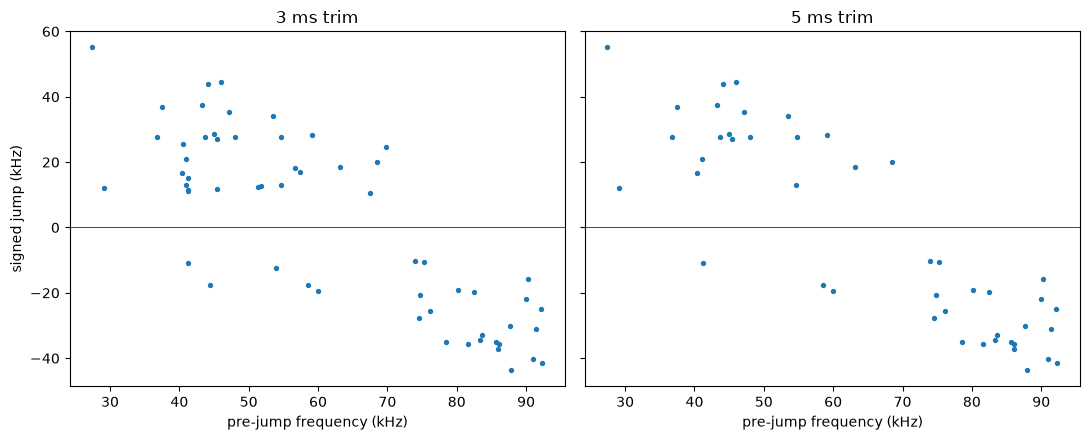

In [8]:
clean5 = jumps[(jumps["from_start"] > 5) & (jumps["to_end"] > 5)]
print(len(clean), "jumps at 3 ms,", len(clean5), "jumps at 5 ms")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, data, name in [(ax[0], clean, "3 ms trim"), (ax[1], clean5, "5 ms trim")]:
    a.scatter(data["pre_khz"], data["signed_jump_khz"], s=8)
    a.axhline(0, color="k", lw=0.5)
    a.set_title(name); a.set_xlabel("pre-jump frequency (kHz)")
ax[0].set_ylabel("signed jump (kHz)")
plt.tight_layout(); plt.show()

In [9]:
c = clean5.copy()
c["ratio"] = c["post_khz"] / c["pre_khz"]
for name, g in c.groupby(c["signed_jump_khz"] > 0):
    print("up" if name else "down", len(g), "jumps")
    print(" landing (kHz): median %.1f, spread (std) %.1f" % (g["post_khz"].median(), g["post_khz"].std()))
    print(" ratio post/pre: median %.2f, spread (std) %.2f" % (g["ratio"].median(), g["ratio"].std()))

down 25 jumps
 landing (kHz): median 50.6, spread (std) 10.3
 ratio post/pre: median 0.66, spread (std) 0.10
up 20 jumps
 landing (kHz): median 78.3, spread (std) 12.5
 ratio post/pre: median 1.61, spread (std) 0.39


In [14]:
out400 = Path("jump_review400"); out400.mkdir(exist_ok=True)
rng = np.random.default_rng(2)
order = rng.permutation(len(wavs))
rows400, n_inc = [], 0
for idx in order:
    if n_inc >= 400:
        break
    p = wavs[int(idx)]
    try:
        rows, audit = ja.inspect_file(p, 10, 2, out400)
    except Exception:
        continue
    if audit["status"] == "included":
        n_inc += 1
        rows400 += rows

jumps400 = pd.DataFrame(rows400)
jumps400.to_csv("jumps400.csv", index=False)
print(n_inc, "files,", len(jumps400), "jumps,", jumps400["file"].nunique(), "files with jumps")

400 files, 299 jumps, 143 files with jumps


In [15]:
odd = jumps[(jumps["pre_khz"] < 65) & (jumps["signed_jump_khz"] < 0)]
print(odd[["file", "pre_khz", "post_khz", "time_ms"]])

                                                 file    pre_khz   post_khz  \
0   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  53.906250  41.367188   
7   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  44.414062  26.718750   
8   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  58.593750  40.898438   
15  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  41.250000  30.468750   
69  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  64.687500  40.546875   
71  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  60.000000  40.429688   

      time_ms  
0    5.866667  
7   24.533333  
8   17.600000  
15  23.466667  
69   9.600000  
71  59.733333  


In [16]:
print(odd["file"].map(lambda p: Path(p).name).tolist())

['DBA_3170_841.WAV', 'DBA_3248_672.WAV', 'DBA_3243_53.WAV', 'DBA_3248_535.WAV', 'DBA_3243_291.WAV', 'DBA_3243_291.WAV']


In [17]:
spans = {p: call_span(p) for p in jumps400["file"].unique()}
jumps400["from_start"] = jumps400["time_ms"] - jumps400["file"].map(lambda p: spans[p][0])
jumps400["to_end"] = jumps400["file"].map(lambda p: spans[p][1]) - jumps400["time_ms"]
c400 = jumps400[(jumps400["from_start"] > 5) & (jumps400["to_end"] > 5)]
c400.to_csv("c400.csv", index=False)
print(len(jumps400), "->", len(c400), "jumps after a 5 ms trim")

299 -> 187 jumps after a 5 ms trim


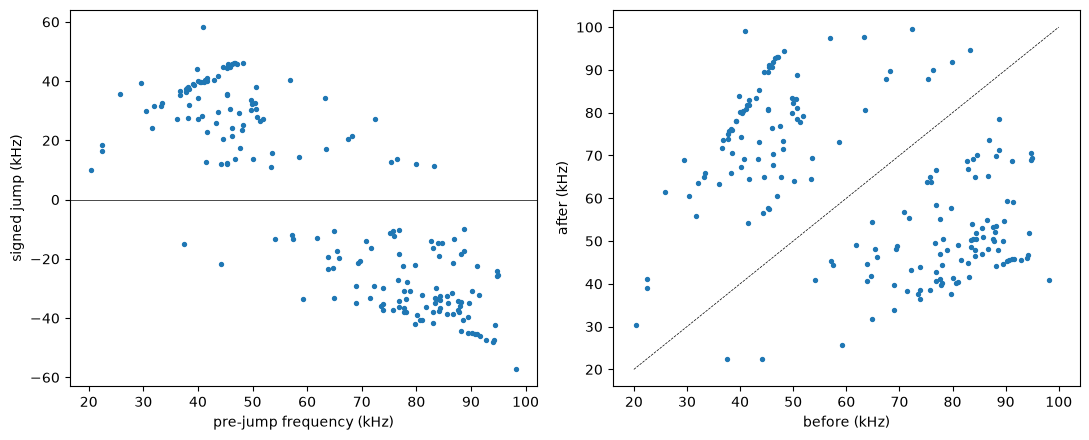

down 100 | landing median 48.0 std 11.1 | ratio median 0.60 std 0.12
up 87 | landing median 77.8 std 13.5 | ratio median 1.75 std 0.31


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(c400["pre_khz"], c400["signed_jump_khz"], s=8)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("pre-jump frequency (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[1].scatter(c400["pre_khz"], c400["post_khz"], s=8)
ax[1].plot([20, 100], [20, 100], "k--", lw=0.5)
ax[1].set_xlabel("before (kHz)"); ax[1].set_ylabel("after (kHz)")
plt.tight_layout(); plt.show()

c400 = c400.assign(ratio=c400["post_khz"] / c400["pre_khz"])
for name, g in c400.groupby(c400["signed_jump_khz"] > 0):
    print("up" if name else "down", len(g),
          "| landing median %.1f std %.1f" % (g["post_khz"].median(), g["post_khz"].std()),
          "| ratio median %.2f std %.2f" % (g["ratio"].median(), g["ratio"].std()))

In [19]:
up = c400[c400["signed_jump_khz"] > 0]
print("upward jumps:", len(up))
print("landing above 95 kHz:", (up["post_khz"] > 95).sum())
print("starts above 55 kHz (1.7x would exceed 93 kHz):", (up["pre_khz"] > 55).sum())
print("all jumps starting above 55 kHz, up vs down:",
      (c400[c400["pre_khz"] > 55]["signed_jump_khz"] > 0).sum(), "up,",
      (c400[c400["pre_khz"] > 55]["signed_jump_khz"] < 0).sum(), "down")

upward jumps: 87
landing above 95 kHz: 4
starts above 55 kHz (1.7x would exceed 93 kHz): 11
all jumps starting above 55 kHz, up vs down: 11 up, 97 down
